# Tarea 22: Práctica SVM

### Carga de librearias y datos

In [1]:
# Load libraries for this notebook

import pandas as pd
import pylab as pl
import numpy as np
import scipy.optimize as opt
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [6]:
# Load the data
data_frame_original = pd.read_csv('recursos_humanos.csv')
data_frame_original.sample(5)


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
14952,0.44,0.52,2,149,3,0,1,0,marketing,low
9937,0.91,0.98,5,135,3,0,0,0,sales,low
13006,0.56,0.74,3,154,2,0,0,0,hr,medium
2119,0.5,0.95,5,207,3,0,0,0,technical,low
13494,0.66,0.85,3,178,8,1,0,0,marketing,medium


Verificación de nulos y los tipos de datos en el data set

In [7]:
data_frame_original.info()

<class 'pandas.DataFrame'>
RangeIndex: 29999 entries, 0 to 29998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   satisfaction_level     29999 non-null  str  
 1   last_evaluation        29999 non-null  str  
 2   number_project         29999 non-null  str  
 3   average_montly_hours   29999 non-null  str  
 4   time_spend_company     29999 non-null  str  
 5   Work_accident          29999 non-null  str  
 6   left                   29999 non-null  str  
 7   promotion_last_5years  29999 non-null  str  
 8   sales                  29999 non-null  str  
 9   salary                 29999 non-null  str  
dtypes: str(10)
memory usage: 2.3 MB


### Convertir los datos a tipo numerico

Conversion de los datos de tipo cadena a tipo numerico

In [ ]:
data_frame = data_frame_original.copy()

# Function to convert str values to numeric values
def convert_to_numeric(df, column_name, type):
    """ Function to convert usually str values to numeric values

    Args:
        df (DataFrame): DataFrame to be processed
        column_name (str): Name of the column to be converted
        type (str): Type to convert the column to (e.g., 'int', 'float')
    Returns:
        DataFrame: DataFrame with the specified column converted to numeric values
    """
    
    df = df[pd.to_numeric(df[column_name], errors='coerce').notnull()]
    df[column_name] = df[column_name].astype(type)
    return df

# Apply the function to convert the columns 'satisfaction_level', 'last_evaluation', 'number_project', 'time_spend_company', 'Work_accident', 'promotion_last_5years',
# and 'average_montly_hours', 'left',  to numeric values

data_frame = convert_to_numeric(data_frame, 'satisfaction_level', 'float')
data_frame = convert_to_numeric(data_frame, 'last_evaluation', 'float')
data_frame = convert_to_numeric(data_frame, 'number_project', 'int')
data_frame = convert_to_numeric(data_frame, 'time_spend_company', 'int')
data_frame = convert_to_numeric(data_frame, 'Work_accident', 'int')
data_frame = convert_to_numeric(data_frame, 'promotion_last_5years', 'int')
data_frame = convert_to_numeric(data_frame, 'average_montly_hours', 'float')
data_frame = convert_to_numeric(data_frame, 'left', 'int')

data_frame.info()
data_frame.sample(5)


<class 'pandas.DataFrame'>
Index: 29998 entries, 0 to 29998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     29998 non-null  float64
 1   last_evaluation        29998 non-null  float64
 2   number_project         29998 non-null  int64  
 3   average_montly_hours   29998 non-null  float64
 4   time_spend_company     29998 non-null  int64  
 5   Work_accident          29998 non-null  int64  
 6   left                   29998 non-null  int64  
 7   promotion_last_5years  29998 non-null  int64  
 8   sales                  29998 non-null  str    
 9   salary                 29998 non-null  str    
dtypes: float64(3), int64(5), str(2)
memory usage: 2.5 MB


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
22949,0.76,0.99,3,166.0,3,0,0,0,sales,medium
5145,0.63,0.92,2,198.0,2,0,0,0,hr,low
5771,0.53,0.60,5,247.0,3,0,0,0,technical,low
11888,0.70,0.54,3,194.0,2,1,0,0,IT,low
24857,0.54,0.87,4,163.0,3,0,0,0,sales,medium


### Codificación de variables categóricas

Las variables categoricas encontradas en los datos son: 'sales' y 'salary', se va a usar la función get_dummies de pandas para remplazarlarlas por valores numéricos.

In [15]:
data_frame_updated = pd.get_dummies(data_frame, columns=['sales', 'salary'], dtype= float)
data_frame_updated.sample(5)

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales_IT,sales_RandD,...,sales_hr,sales_management,sales_marketing,sales_product_mng,sales_sales,sales_support,sales_technical,salary_high,salary_low,salary_medium
21521,0.72,0.83,3,132.0,2,0,0,0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
18187,0.56,0.90,4,115.0,3,0,0,0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
5634,0.23,0.49,5,214.0,5,0,0,0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
239,0.10,0.97,7,254.0,4,0,1,0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
21436,0.29,0.86,3,251.0,4,0,0,0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


### Modelo predictivo con el método de SVM

#### Definición de las variables para aplicar el modelo

In [7]:
X_non_normalized = data_frame_updated.drop('left', axis= 1)

Y = data_frame_updated['left']   
X_non_normalized.info()

<class 'pandas.DataFrame'>
RangeIndex: 29999 entries, 0 to 29998
Data columns (total 21 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     29999 non-null  str    
 1   last_evaluation        29999 non-null  str    
 2   number_project         29999 non-null  str    
 3   average_montly_hours   29999 non-null  str    
 4   time_spend_company     29999 non-null  str    
 5   Work_accident          29999 non-null  str    
 6   promotion_last_5years  29999 non-null  str    
 7   sales_IT               29999 non-null  float64
 8   sales_RandD            29999 non-null  float64
 9   sales_accounting       29999 non-null  float64
 10  sales_hr               29999 non-null  float64
 11  sales_management       29999 non-null  float64
 12  sales_marketing        29999 non-null  float64
 13  sales_product_mng      29999 non-null  float64
 14  sales_sales            29999 non-null  float64
 15  sales_support

In [6]:
# Data normalization
x = (X_non_normalized - np.min(X_non_normalized)) / (np.max(X_non_normalized) - np.min(X_non_normalized))

TypeError: '<=' not supported between instances of 'str' and 'float'

### Uso del método KNN

In [ ]:
# Data for training and test
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x_normalized, Y, test_size= 0.30, random_state= 1)

### Function para evaluar el método KNN 
Se usan diferentes valores de n = 1, 2, 3 ...

In [ ]:
# get the optimal model for the svm method
from sklearn.svm import SVC

def get_svm(kernel, C):
    ''' Function to estimate the value of the score for svm values

    Args: 
        kernel: the kernel type for the svm
        C: the regularization parameter for the svm
    
    Returns:
        A tuple of the kernel, C, and the score
    '''
    svm = SVC(kernel=kernel, C=C)

    svm.fit(x_train, y_train)

    return kernel, C, svm.score(x_test, y_test)

# Numbers to evaluate the function, 1 - 20
numbers = np.arange(1, 21)

# Predictions from the function
n_predicitions = [get_knn(n) for n in numbers]

n_predicitions



[(np.int64(1), 0.9455555555555556),
 (np.int64(2), 0.942),
 (np.int64(3), 0.9357777777777778),
 (np.int64(4), 0.9411111111111111),
 (np.int64(5), 0.9342222222222222),
 (np.int64(6), 0.9422222222222222),
 (np.int64(7), 0.9384444444444444),
 (np.int64(8), 0.9402222222222222),
 (np.int64(9), 0.9326666666666666),
 (np.int64(10), 0.9366666666666666),
 (np.int64(11), 0.9317777777777778),
 (np.int64(12), 0.9371111111111111),
 (np.int64(13), 0.9326666666666666),
 (np.int64(14), 0.9351111111111111),
 (np.int64(15), 0.9346666666666666),
 (np.int64(16), 0.9346666666666666),
 (np.int64(17), 0.9313333333333333),
 (np.int64(18), 0.9317777777777778),
 (np.int64(19), 0.9324444444444444),
 (np.int64(20), 0.9331111111111111)]

In [ ]:
n_optimal = max(n_predicitions, key=lambda item: item[1])
print(f'The optiomal value is {n_optimal}')

The optiomal value is (np.int64(1), 0.9455555555555556)


In [ ]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=n_optimal[0])

knn.fit(x_train, y_train)

prediction = knn.predict(x_test)

print(f'Score: {knn.score(x_test, y_test)}')

Score: 0.9455555555555556


### Creación de la matriz de confusión

In [ ]:
y_pred = prediction
y_true = y_test

# Creation of the confusion matrix
from sklearn.metrics import confusion_matrix
c_matrix = confusion_matrix(y_true, y_pred)
c_matrix

array([[3234,  182],
       [  63, 1021]])

Los resultados que muestra la matriz de confusion expresan los siguiente, basado en los datos de pruebas:
- 3234 personas que se quedaron
- 1021 personas que se fuero y dejaron el empleo
- 182 es un falso positivo, es decir personas que se irian según la predicción pero que se quedaron
- 63 es un falso negativo, personas que se quedarian pero se quedaron

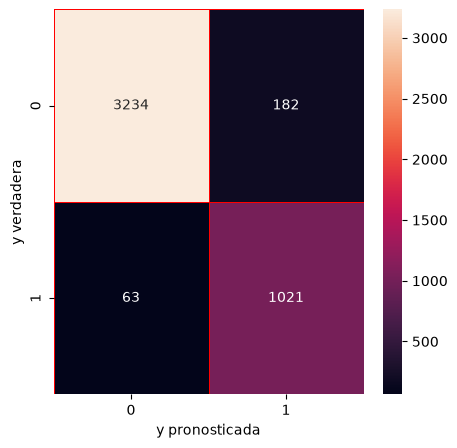

In [ ]:
fig, ax = plt.subplots(figsize = (5, 5))

sns.heatmap(c_matrix, annot= True, linewidths= 0.5, linecolor='red', fmt= '.0f', ax=ax)
plt.xlabel('y pronosticada')
plt.ylabel('y verdadera')
plt.show()

### Càlculo de indicadores

In [ ]:
correct = c_matrix[0, 0] + c_matrix[1, 1]
incorrect = c_matrix[0, 1] + c_matrix[1, 0]
global_accuracy = correct / (correct + incorrect)
global_accuracy

np.float64(0.9455555555555556)

In [ ]:
stayed_accuracy = c_matrix[0, 0] / (c_matrix[0, 0] + c_matrix[1, 0])
stayed_accuracy

np.float64(0.9808917197452229)

In [ ]:
left_accuracy = c_matrix[1, 1] / (c_matrix[1, 1] + c_matrix[0, 1])
left_accuracy

np.float64(0.8487115544472152)

### Cálculo de la curva Roc

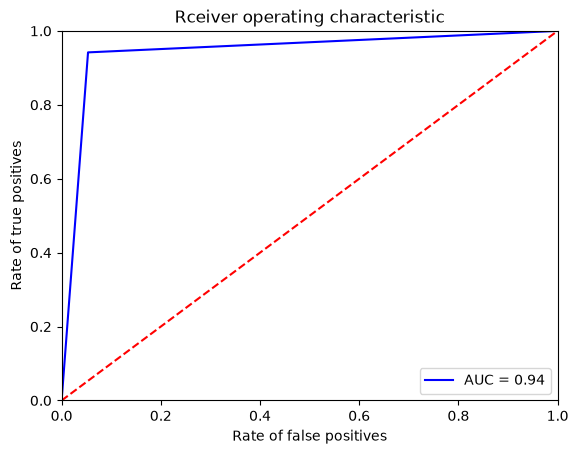

In [ ]:
from sklearn.metrics import roc_curve
from sklearn.metrics import auc

y_score = knn.predict_proba(x_test)

fpr, tpr, threadhold = roc_curve(y_test, y_score[:, 1])
roc_auc = auc(fpr, tpr)

plt.title('Rceiver operating characteristic')
plt.plot(fpr, tpr, 'b', label = 'AUC = %0.2f' % roc_auc)
plt.legend(loc= 'lower right')
plt.plot([0,1], [0,1], 'r--')
plt.xlim([0,1])
plt.ylim([0,1])
plt.ylabel('Rate of true positives')
plt.xlabel('Rate of false positives')
plt.show()

El área de bajo la curva de la grafica ROC muestra que tan bueno es e clasificador en general. El valor obtenido es 0.94 se refiere a un valor muy bueno. Esto es bueno porque a pesar de que los datos no estan balanceados el método KNN tiene una buena predicción sobre si un empleado de quedara o abandonara su posición.